<a href="https://colab.research.google.com/github/Adhin10/AI-ML/blob/main/ANN_AND_KMEANS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ANN


In [ ]:
import numpy as np

# Data: XOR problem
X = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([[0],[1],[1],[0]])

np.random.seed(42)
W1 = np.random.randn(2, 4)   # input -> hidden (4 neurons)
b1 = np.zeros((1, 4))
W2 = np.random.randn(4, 1)   # hidden -> output
b2 = np.zeros((1, 1))
lr = 0.5

def sigmoid(x):  return 1 / (1 + np.exp(-x))
def d_sigmoid(a): return a * (1 - a)   # derivative, given a = sigmoid(x)

for epoch in range(10000):
    # Forward pass
    h = sigmoid(X @ W1 + b1)
    out = sigmoid(h @ W2 + b2)

    # Loss (mean squared error)
    loss = np.mean((y - out) ** 2)

    # Backpropagation
    d_out = (out - y) * d_sigmoid(out)
    d_h = (d_out @ W2.T) * d_sigmoid(h)

    # Gradient descent update
    W2 -= lr * h.T @ d_out
    b2 -= lr * d_out.sum(axis=0, keepdims=True)
    W1 -= lr * X.T @ d_h
    b1 -= lr * d_h.sum(axis=0, keepdims=True)

    if epoch % 2000 == 0:
        print(f"Epoch {epoch}, Loss: {loss:.4f}")

print("Predictions:\n", out.round(3))

Epoch 0, Loss: 0.2832
Epoch 2000, Loss: 0.0028
Epoch 4000, Loss: 0.0008
Epoch 6000, Loss: 0.0004
Epoch 8000, Loss: 0.0003
Predictions:
 [[0.01 ]
 [0.987]
 [0.984]
 [0.017]]


In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report

X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Scale features (neural networks need this)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = MLPClassifier(hidden_layer_sizes=(10, 8), activation='relu',
                      max_iter=1000, random_state=42)
model.fit(X_train, y_train)

pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, pred))
print(classification_report(y_test, pred))

Accuracy: 0.9333333333333333
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



# CLUSTERING KMEANS

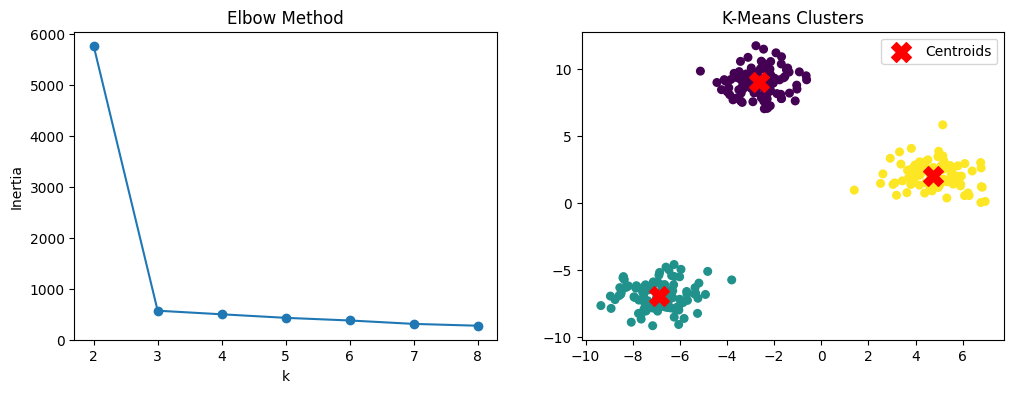

Silhouette score (k=3): 0.8480303059596955


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Generate sample data with 3 natural groups
X, _ = make_blobs(n_samples=300, centers=3, cluster_std=1.0, random_state=42)

# Elbow method: find a good k
inertias, sil_scores = [], []
K = range(2, 9)
for k in K:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X, km.labels_))

# Final model
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
labels = kmeans.fit_predict(X)

# Plots
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(K, inertias, marker='o')
ax[0].set(title="Elbow Method", xlabel="k", ylabel="Inertia")

ax[1].scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=30)
ax[1].scatter(*kmeans.cluster_centers_.T, c='red', marker='X', s=200, label='Centroids')
ax[1].set_title("K-Means Clusters")
ax[1].legend()
plt.show()

print("Silhouette score (k=3):", silhouette_score(X, labels))